# 144 · Runtime monitors: sample disagreement of a flow policy as an out-of-distribution alarm

In [1]:
import os, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import FlowPolicy, ChunkPolicy
from vlacourse.eval_suite import SUITE

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
H = 16

class MonitoredPolicy(ChunkPolicy):
    """At every replanning point, draw K chunks and record their spread (in normalized action units)."""
    def __init__(self, *a, K=8, **kw):
        super().__init__(*a, **kw); self.K = K; self.spreads = []
    def _chunk(self, obs):
        b = self._batch(obs); b = {k: v.repeat(self.K, *[1] * (v.dim() - 1)) for k, v in b.items()}
        out = self.net.sample(b, nfe=self.nfe).cpu().numpy()
        self.spreads.append(float(out[:, :8, :3].std(0).mean()))
        return self.ds.to_absolute(np.stack([self.ds.act_norm.unnorm(a) for a in out[0]]), obs)   # rel chunk -> command targets

def run(env, pol, perturb, seed):
    obs = env.reset(seed=seed); perturb(env); obs = env.observe(); pol.reset(); pol.spreads = []; done = False
    while not done:
        obs, _, done, info = env.step(pol.act(obs))
    return info["success"], np.mean(pol.spreads)

In [2]:
ds = TableTopDataset(DATA, episodes=range(450), horizon=H)
from vlacourse import need; need("../S08_Generative_Action_Heads/checkpoints/flow.pt", "S08 notebook 81")
flow = FlowPolicy(horizon=H); flow.load_state_dict(torch.load("../S08_Generative_Action_Heads/checkpoints/flow.pt", map_location=device)); flow.to(device).eval()
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
pol = MonitoredPolicy(flow, ds, env, device, execute=8, nfe=4)
conds = {p.name: p.apply_fn for p in SUITE if p.name in ("nominal", "camera +6 cm / lower", "dim light (x0.5)", "grey table")}
records = []
for name, fn in conds.items():
    for s in range(20):
        ok, spread = run(env, pol, fn, 300 + s); records.append((name, ok, spread))
    from vlacourse.eval_suite import _restore_all; _restore_all(env)
    sub = [r for r in records if r[0] == name]
    print(f"{name:22s} success {np.mean([r[1] for r in sub]):.2f}  mean sample spread {np.mean([r[2] for r in sub]):.3f}")

nominal                success 1.00  mean sample spread 0.040


camera +6 cm / lower   success 0.90  mean sample spread 0.039


dim light (x0.5)       success 0.75  mean sample spread 0.035


grey table             success 0.75  mean sample spread 0.036


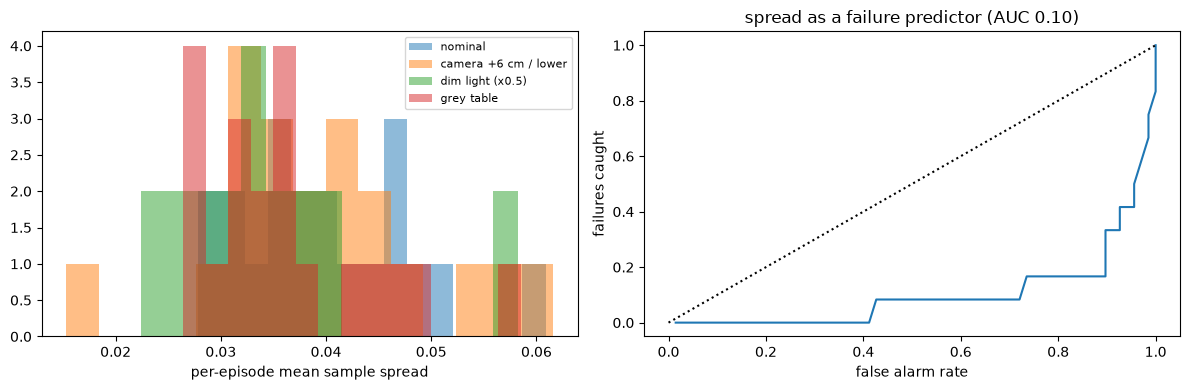

In [3]:
spread = np.array([r[2] for r in records]); fail = np.array([not r[1] for r in records])
ths = np.quantile(spread, np.linspace(0, 1, 50))
tpr = [(spread[fail] >= t).mean() for t in ths]; fpr = [(spread[~fail] >= t).mean() for t in ths]
auc = (getattr(np, "trapezoid", None) or np.trapz)(tpr[::-1], fpr[::-1])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in conds:
    ax[0].hist([r[2] for r in records if r[0] == name], bins=15, alpha=0.5, label=name)
ax[0].set_xlabel("per-episode mean sample spread"); ax[0].legend(fontsize=8)
ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_xlabel("false alarm rate"); ax[1].set_ylabel("failures caught"); ax[1].set_title(f"spread as a failure predictor (AUC {auc:.2f})")
plt.tight_layout(); plt.show()

### Watch it: what the monitor is watching
Nominal vs a moved camera: the policy's action samples spread out before it fails.

In [4]:
from vlacourse import showcase as sc
from vlacourse.eval_suite import _restore_all
def perturbed(fn):
    return lambda e: (_restore_all(e), fn(e))
sfx = {p.name: p.apply_fn for p in SUITE}
sc.compare(env, {"nominal": pol, "camera moved 6 cm": pol}, seed=301,
           per_policy_kw={"nominal": dict(on_reset=perturbed(sfx["nominal"])), "camera moved 6 cm": dict(on_reset=perturbed(sfx["camera +6 cm / lower"]))},
           title="144 nominal vs moved camera")
_restore_all(env)

144 nominal vs moved camera: nominal: success | camera moved 6 cm: success
